In [1]:
using Oceananigans, CairoMakie
using ColorSchemes
using MPI

In [2]:
loc = "/nfs/hpc/share/carlipp/ngpu-scaling/strong/"
ds_1gpu = FieldDataset(loc*"1-gpu_rank0.jld2"; backend = OnDisk())
ds_2gpu = FieldDataset(loc*"2-gpu_rank0.jld2"; backend = OnDisk())
ds_4gpu = FieldDataset(loc*"4-gpu_rank0.jld2"; backend = OnDisk())

FieldDataset with 5 fields and 0 metadata entries:
├── KE: 1×1×1×17 FieldTimeSeries{OnDisk} located at (⋅, ⋅, ⋅) of KE at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
├── dissipation: 1×1×1×17 FieldTimeSeries{OnDisk} located at (⋅, ⋅, ⋅) of dissipation at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
├── u: 256×1024×512×17 FieldTimeSeries{OnDisk} located at (Face, Center, Center) of u at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
├── v: 256×1024×512×17 FieldTimeSeries{OnDisk} located at (Center, Face, Center) of v at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2
└── w: 256×1024×512×17 FieldTimeSeries{OnDisk} located at (Center, Center, Face) of w at /nfs/hpc/share/carlipp/ngpu-scaling/strong/4-gpu_rank0.jld2


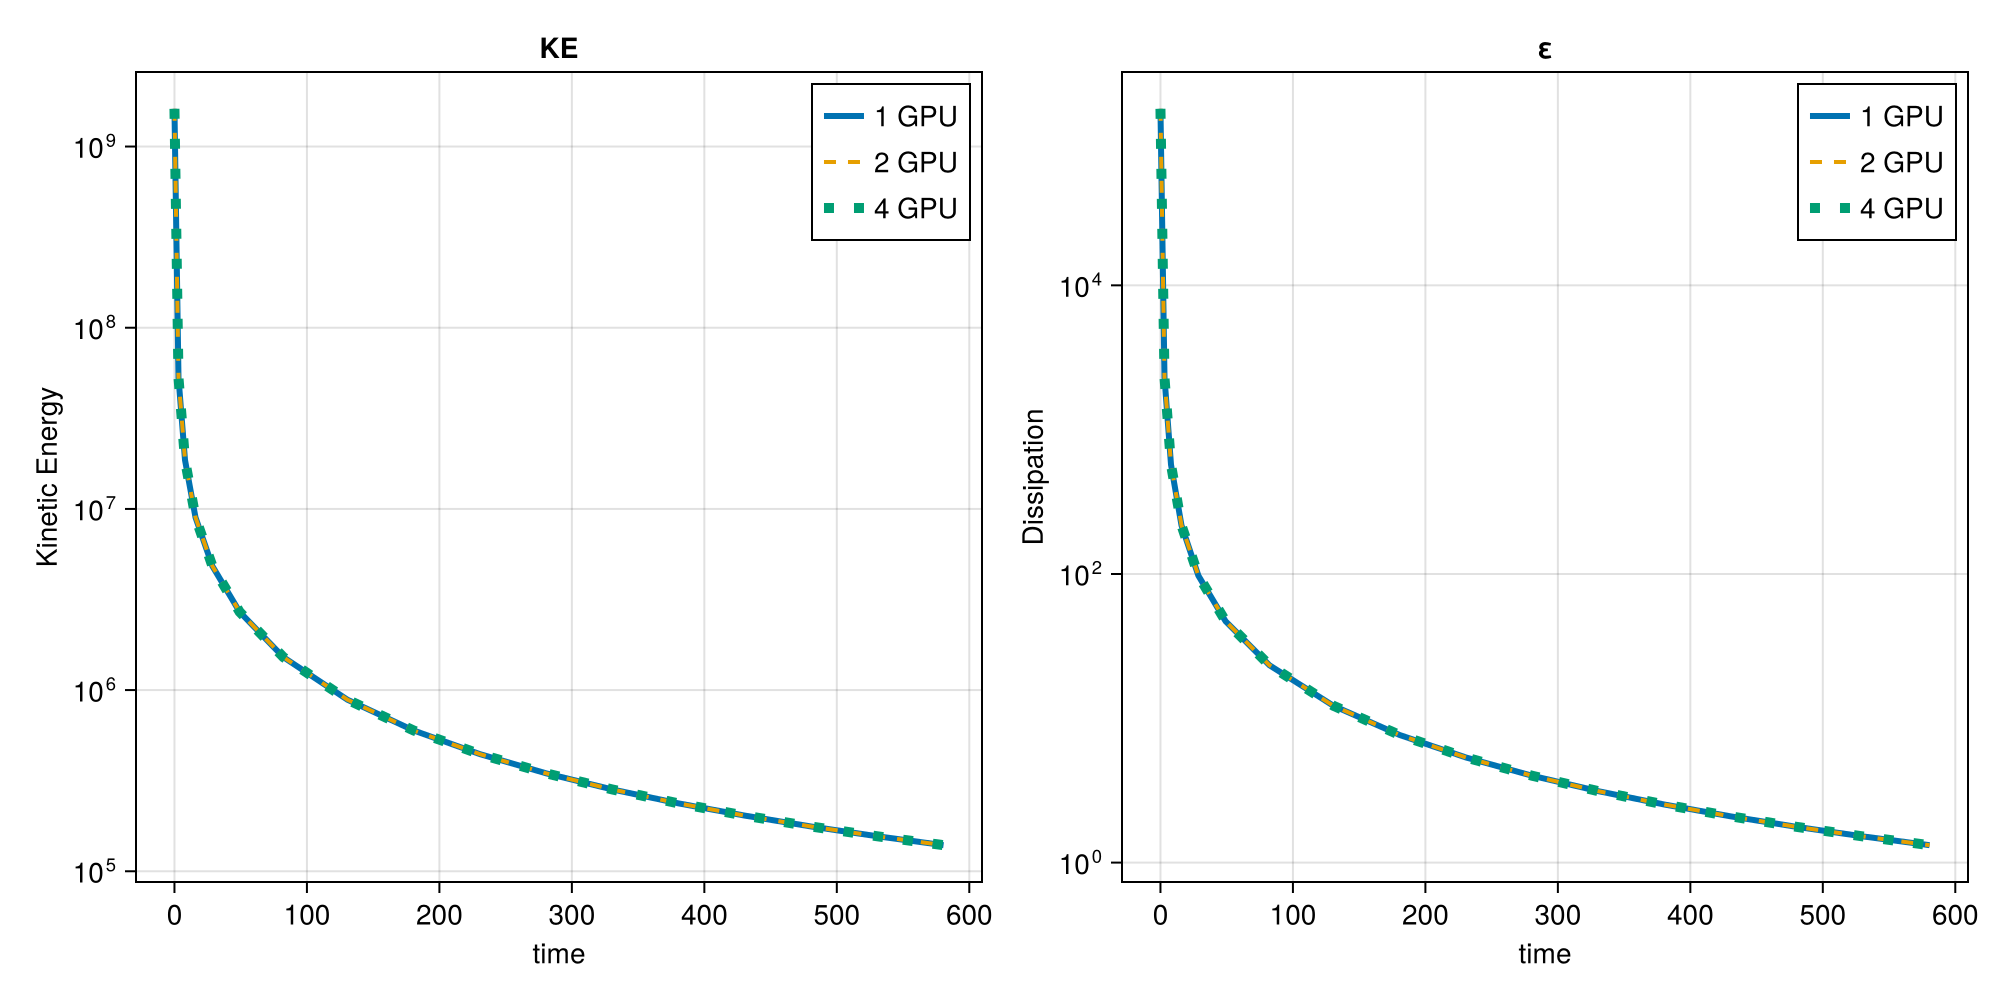

In [3]:
fig = Figure(size = (1000, 500))
ax = Axis(fig[1, 1], yscale = log10, title = "KE", ylabel = "Kinetic Energy", xlabel = "time")
ax2 = Axis(fig[1, 2], yscale = log10, title = "ε", ylabel = "Dissipation", xlabel = "time")
lines!(ax, ds_1gpu.KE, label = "1 GPU", linewidth = 3)
lines!(ax, ds_2gpu.KE, label = "2 GPU", linestyle = :dash, linewidth = 2)
lines!(ax, ds_4gpu.KE, label = "4 GPU", linestyle = :dot, linewidth = 5)
lines!(ax2, ds_1gpu.dissipation, label = "1 GPU", linewidth = 3)
lines!(ax2, ds_2gpu.dissipation, label = "2 GPU", linestyle = :dash, linewidth = 2)
lines!(ax2, ds_4gpu.dissipation, label = "4 GPU", linestyle = :dot, linewidth = 5)
axislegend(ax)
axislegend(ax2)
fig

In [4]:
n = size(ds_1gpu.KE)[end]

17

In [5]:
ke_1 = [collect(ds_1gpu.KE[i])[1] for i = 1:n]
ke_2 = [collect(ds_2gpu.KE[i])[1] for i = 1:n]
ke_4 = [collect(ds_4gpu.KE[i])[1] for i = 1:n];

In [6]:
println(ke_1)
println(ke_2)
println(ke_4)

Float32[1.6149123f9, 5.2865396f7, 1.8597358f7, 8.974678f6, 4.8329395f6, 2.702588f6, 1.5191509f6, 884981.1, 598448.94, 443121.4, 347193.47, 282785.78, 236936.28, 202859.11, 176673.14, 156002.98, 139323.38]
Float32[1.6149123f9, 5.2865396f7, 1.8597358f7, 8.974678f6, 4.832939f6, 2.702588f6, 1.5191509f6, 884981.4, 598448.9, 443121.38, 347193.28, 282786.0, 236936.94, 202859.97, 176674.19, 156004.06, 139324.73]
Float32[1.6149123f9, 5.2865396f7, 1.8597356f7, 8.974678f6, 4.832939f6, 2.7025875f6, 1.5191485f6, 884979.44, 598448.4, 443123.47, 347197.16, 282789.56, 236938.72, 202858.42, 176669.75, 155997.73, 139317.56]


In [7]:
isapprox(ke_1, ke_2, rtol = 1e-5)

true

In [8]:
isapprox(ke_2, ke_4, rtol = 1e-5)

true

In [9]:
u1 = FieldTimeSeries(loc*"1-gpu", "u"; backend = OnDisk())
u2 = FieldTimeSeries(loc*"2-gpu", "u"; backend = OnDisk())
u4 = FieldTimeSeries(loc*"4-gpu", "u"; backend = OnDisk());

In [10]:
u1slice = interior(u1[end])[:, :, 10]
u2slice = interior(u2[end])[:, :, 10]
u4slice = interior(u4[end])[:, :, 10];

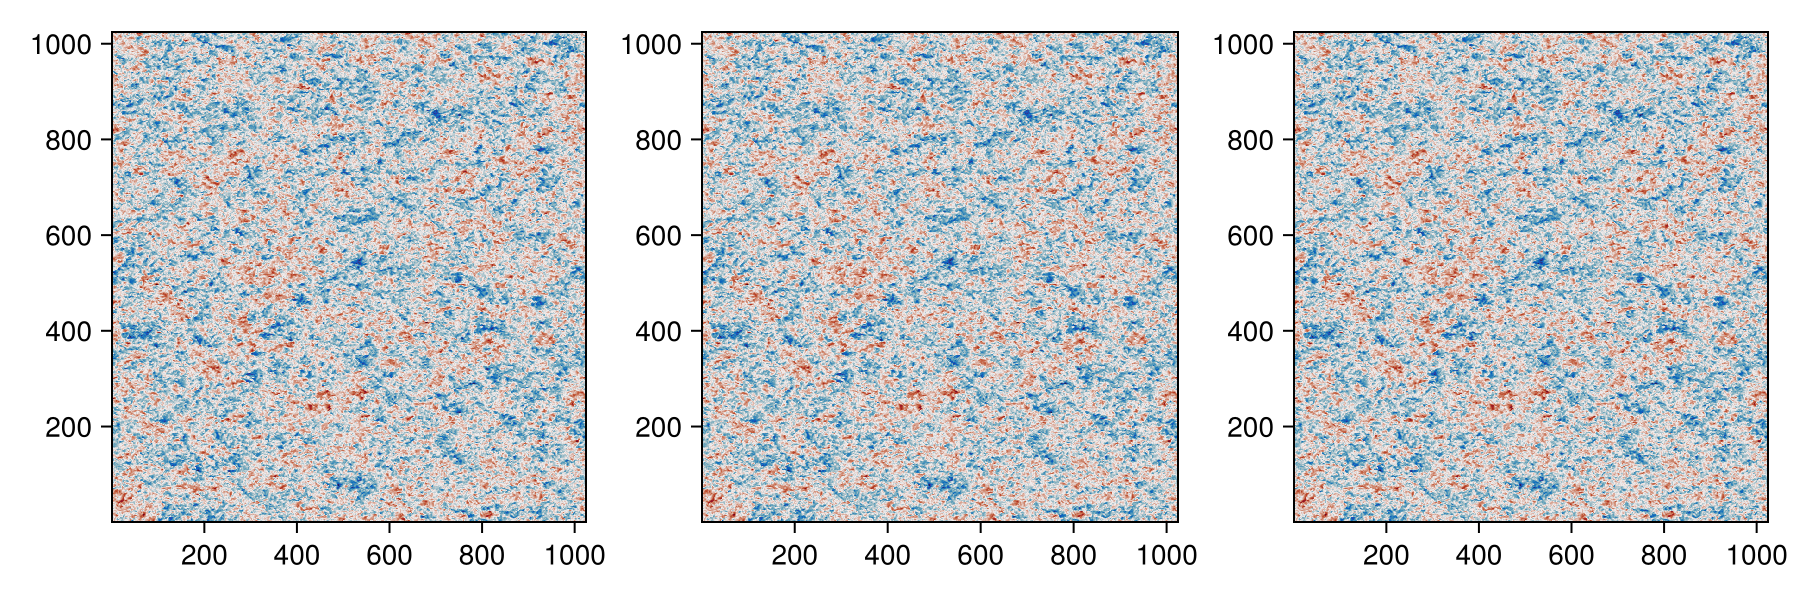

In [11]:
fig = Figure(size = (900, 300))
ax1 = Axis(fig[1, 1])
ax2 = Axis(fig[1, 2])
ax3 = Axis(fig[1, 3])
heatmap!(ax1, u1slice, colormap = :balance)
heatmap!(ax2, u2slice, colormap = :balance)
heatmap!(ax3, u4slice, colormap = :balance)
fig

In [12]:
u1_end = interior(u1[end])
u2_end = interior(u2[end])
u4_end = interior(u4[end]);

In [13]:
using Statistics

println(std(u1_end))
println(std(u2_end))
println(std(u4_end))
println(std(u1_end-u2_end))
println(std(u1_end-u4_end))

0.019013949816751516
0.019014081659075248
0.019013818179913752
0.0017473707278657371
0.004048613110727481
